Load stuff

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

diabetes_df = pd.read_csv('diabetes.csv')

# Check the first few rows of the dataframe
print(diabetes_df.head())

# Check the dimensions of the dataframe
print(diabetes_df.shape)

print(diabetes_df.columns)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
(768, 9)
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


## Question 1

In [2]:
# Step 2: Display the value counts of the Outcome variable
outcome_counts = diabetes_df['Outcome'].value_counts()
print("Value Counts:\n", outcome_counts)

# Step 3: Calculate the total number of samples
total_samples = len(diabetes_df)

# Step 4: Calculate the percentage of diabetic cases (Outcome == 1)
diabetic_count = outcome_counts.get(1, 0)
diabetic_percentage = (diabetic_count / total_samples) * 100

print(f"Total Samples: {total_samples}")
print(f"Diabetic Cases: {diabetic_count}")
print(f"Percentage of Diabetic Cases: {diabetic_percentage:.2f}%")

Value Counts:
 Outcome
0    500
1    268
Name: count, dtype: int64
Total Samples: 768
Diabetic Cases: 268
Percentage of Diabetic Cases: 34.90%


## Question 2

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Step 1: Prepare features (X) and target (y)
X = diabetes_df.drop(columns=['Outcome'])
y = diabetes_df['Outcome']

# Step 2: Standardize the features (important for regularization)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 3: Split into train and test sets (not strictly required for feature selection, but good practice)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Step 4: Train logistic regression with L1 penalty (Lasso-like feature selection)
logreg_l1 = LogisticRegression(penalty='l1', solver='liblinear', C=1.0)  # C is inverse of regularization strength
logreg_l1.fit(X_train, y_train)

# Step 5: Get feature names and their corresponding coefficients
feature_names = diabetes_df.drop(columns=['Outcome']).columns
coefficients = logreg_l1.coef_[0]

# Step 6: Identify selected features (non-zero coefficients)
selected_features = [(name, coef) for name, coef in zip(feature_names, coefficients) if coef != 0]

# Step 7: Print selected features
print("Selected Features with L1 penalty:")
for name, coef in selected_features:
    print(f"{name}: {coef:.4f}")


Selected Features with L1 penalty:
Pregnancies: 0.2088
Glucose: 1.0599
BloodPressure: -0.2425
SkinThickness: 0.0269
Insulin: -0.1827
BMI: 0.7854
DiabetesPedigreeFunction: 0.2183
Age: 0.4208


## Question 3

In [4]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Step 1: Define features (X) and target (y)
X = diabetes_df.drop(columns=["Outcome"])
y = diabetes_df["Outcome"]

# Step 2: Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 3: Convert scaled data back to DataFrame to retain column names
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# Step 4: Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled_df, y, test_size=0.2, random_state=42)

# Step 5: Train Random Forest Classifier
rfc = RandomForestClassifier(random_state=42)
rfc.fit(X_train, y_train)

# Step 6: Extract feature names and importances
feature_names = rfc.feature_names_in_
importances = rfc.feature_importances_

# Step 7: Combine and sort
feature_importance = sorted(zip(feature_names, importances), key=lambda x: x[1], reverse=True)

# Step 8: Display results
print("Feature Importances from Random Forest:")
for name, score in feature_importance:
    print(f"{name}: {score:.4f}")


Feature Importances from Random Forest:
Glucose: 0.2589
BMI: 0.1700
Age: 0.1409
DiabetesPedigreeFunction: 0.1238
BloodPressure: 0.0881
Pregnancies: 0.0766
Insulin: 0.0761
SkinThickness: 0.0656


## Question 4

In [5]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from lime.lime_tabular import LimeTabularExplainer

# Step 1: Prepare data
X = diabetes_df.drop(columns=['Outcome'])
y = diabetes_df['Outcome']

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled_df, y, test_size=0.2, random_state=42)

# Step 2: Train the model
rfc = RandomForestClassifier(random_state=42)
rfc.fit(X_train, y_train)

# Step 3: Choose a datapoint to explain
i = 0  # Index of the test sample to explain
instance_to_explain = X_test.iloc[i]

# Step 4: Set up LIME explainer
explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=["No Diabetes", "Diabetes"],
    mode='classification',
    discretize_continuous=False
)

# Step 5: Generate explanation
exp = explainer.explain_instance(
    data_row=instance_to_explain.values,
    predict_fn=rfc.predict_proba,
    num_features=8
)

# Step 6: Display results
print(f"Explanation for test instance {i}:")
for feature, weight in exp.as_list():
    print(f"{feature}: {weight:.4f}")


Explanation for test instance 0:
Glucose: 0.1337
BMI: 0.0956
Age: 0.0670
DiabetesPedigreeFunction: 0.0530
Pregnancies: 0.0221
SkinThickness: 0.0073
BloodPressure: -0.0049
Insulin: 0.0027


/Users/chan/miniconda3/envs/stat415_hw3_env/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


## Question 5

In [6]:
from lime.lime_tabular import LimeTabularExplainer
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Step 1: Prepare data
X = diabetes_df.drop(columns=['Outcome'])
y = diabetes_df['Outcome']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

X_train, X_test, y_train, y_test = train_test_split(X_scaled_df, y, test_size=0.2, random_state=42)

# Step 2: Train Random Forest
rfc = RandomForestClassifier(random_state=42)
rfc.fit(X_train, y_train)

# Step 3: Set up LIME explainer
explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=["No Diabetes", "Diabetes"],
    mode='classification',
    discretize_continuous=False
)

# Step 4: Explain five different instances
feature_sets = []
num_instances = 5

for i in range(num_instances):
    instance = X_test.iloc[i]
    exp = explainer.explain_instance(instance.values, rfc.predict_proba, num_features=8)
    features = [feature for feature, weight in exp.as_list()]
    feature_sets.append((i, features))

# Step 5: Display feature sets for each instance
for i, features in feature_sets:
    print(f"\nTop features for test instance {i}:")
    for f in features:
        print(f"  {f}")

# Step 6: Analyze overlap across all instances
all_features = [set(f[1]) for f in feature_sets]

common_features = set.intersection(*all_features)
unique_features = set.union(*all_features)

print("\n✅ Common features across all 5 instances:")
print(common_features)

print("\n🔀 Total unique features used across 5 instances:")
print(unique_features)

# Optional: show which features appear how many times
from collections import Counter

flat_features = [feat for features in all_features for feat in features]
feature_counts = Counter(flat_features)

print("\n📊 Feature frequency across explanations:")
for feature, count in feature_counts.items():
    print(f"{feature}: {count}/5")


/Users/chan/miniconda3/envs/stat415_hw3_env/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



Top features for test instance 0:
  Glucose
  BMI
  Age
  DiabetesPedigreeFunction
  Pregnancies
  SkinThickness
  BloodPressure
  Insulin

Top features for test instance 1:
  Glucose
  BMI
  Age
  DiabetesPedigreeFunction
  Pregnancies
  SkinThickness
  BloodPressure
  Insulin

Top features for test instance 2:
  Glucose
  BMI
  Age
  DiabetesPedigreeFunction
  Pregnancies
  BloodPressure
  SkinThickness
  Insulin

Top features for test instance 3:
  Glucose
  BMI
  Age
  DiabetesPedigreeFunction
  Pregnancies
  BloodPressure
  SkinThickness
  Insulin

Top features for test instance 4:
  Glucose
  BMI
  Age
  DiabetesPedigreeFunction
  Pregnancies
  SkinThickness
  BloodPressure
  Insulin

✅ Common features across all 5 instances:
{'DiabetesPedigreeFunction', 'Glucose', 'SkinThickness', 'Age', 'Insulin', 'BloodPressure', 'BMI', 'Pregnancies'}

🔀 Total unique features used across 5 instances:
{'DiabetesPedigreeFunction', 'Glucose', 'SkinThickness', 'BloodPressure', 'Age', 'Insulin', '

/Users/chan/miniconda3/envs/stat415_hw3_env/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/Users/chan/miniconda3/envs/stat415_hw3_env/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/Users/chan/miniconda3/envs/stat415_hw3_env/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/Users/chan/miniconda3/envs/stat415_hw3_env/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


## Question 6:

In [24]:
import pandas as pd
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Step 1: Prepare the dataset
X = diabetes_df.drop(columns=['Outcome'])
y = diabetes_df['Outcome']

# Step 2: Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# Step 3: Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled_df, y, test_size=0.2, random_state=42
)

# Step 4: Train the model
rfc = RandomForestClassifier(random_state=42)
rfc.fit(X_train, y_train)

# ✅ Step 5: Use TreeExplainer with model_output="probability" AND background data
explainer = shap.TreeExplainer(
    model=rfc,
    data=X_train,  # background dataset is required
    model_output="probability"
)

# ✅ Step 6: Compute SHAP values (disable strict additivity check)
shap_values_train = explainer.shap_values(X_train, check_additivity=False)
shap_vals_class1_train = shap_values_train[1]  # Class 1: Diabetes

# Step 7: Check shape
print("X_train shape:", X_train.shape)
print("SHAP values shape:", shap_vals_class1_train.shape)

# Step 8: Global summary plot
shap.summary_plot(
    shap_vals_class1_train,
    X_train,
    feature_names=X_train.columns.tolist()
)

# Step 9: Local force plot
shap_values_test = explainer.shap_values(X_test, check_additivity=False)
shap_vals_class1_test = shap_values_test[1]

shap.initjs()
shap.force_plot(
    base_value=explainer.expected_value[1],
    shap_values=shap_vals_class1_test[0],
    features=X_test.iloc[0],
    feature_names=X_test.columns.tolist()
)


X_train shape: (614, 8)
SHAP values shape: (8, 2)


AssertionError: The shape of the shap_values matrix does not match the shape of the provided data matrix.

<Figure size 640x480 with 0 Axes>



=== Task 6: SHAP Feature Attribution ===
Shape of SHAP matrix for class 1 (positive prediction): (154, 8)
Creating SHAP global summary visualization...


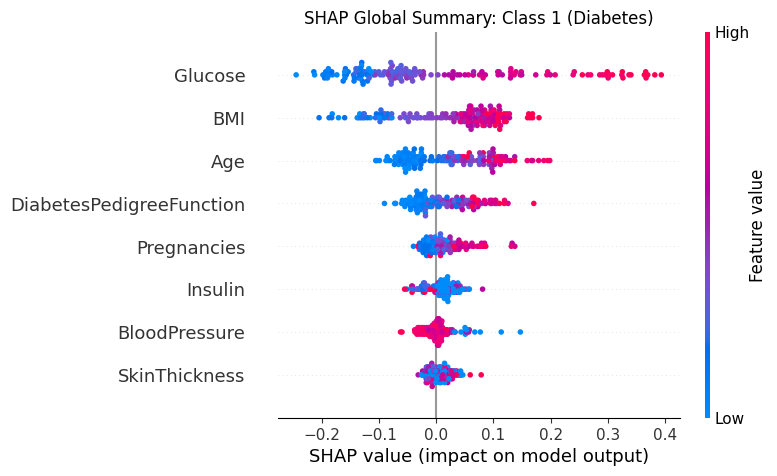

Generating SHAP Force Plot for sample 668...


Force plot stored in HTML format.


In [31]:
import os
from sklearn.ensemble import RandomForestClassifier
import shap
import matplotlib.pyplot as plt

idx_to_explain_1 = 0  # or any integer index within range(len(X_test))


# === Task 6: SHAP-Based Interpretation for Random Forest ===
print("\n\n=== Task 6: SHAP Feature Attribution ===")

# Re-initialize and retrain a new Random Forest model with defined parameters
rf_model = RandomForestClassifier(n_estimators=100, max_depth=100, random_state=42)
rf_model.fit(X_train, y_train)

# Create a SHAP explainer object using the training features as reference background
tree_shap = shap.TreeExplainer(model=rf_model, data=X_train)
shap_raw = tree_shap.shap_values(X_test, check_additivity=False)

# Extract SHAP values corresponding to class label 1 (positive outcome)
if isinstance(shap_raw, np.ndarray) and shap_raw.ndim == 3:
    shap_c1 = shap_raw[:, :, 1]
    base_val_c1 = tree_shap.expected_value[1]
elif isinstance(shap_raw, list) and len(shap_raw) == 2:
    shap_c1 = shap_raw[1]
    base_val_c1 = tree_shap.expected_value[1]
else:
    raise ValueError("Unexpected SHAP format encountered.")

print(f"Shape of SHAP matrix for class 1 (positive prediction): {shap_c1.shape}")

# === Visualize global feature relevance using SHAP summary plot ===
print("Creating SHAP global summary visualization...")
plt.figure()
shap.summary_plot(shap_c1, X_test, feature_names=feature_names, show=False)
plt.title("SHAP Global Summary: Class 1 (Diabetes)")
# Define directory to save plots
plot_dir = "plots"
os.makedirs(plot_dir, exist_ok=True)
plt.savefig(os.path.join(plot_dir, "06a_pima_shap_summary_plot.pdf"))
plt.show()

# === Visualize individual prediction explanation using force plot ===
print(f"Generating SHAP Force Plot for sample {X_test.index[idx_to_explain_1]}...")
shap.initjs()
force_fig = shap.force_plot(
    base_val_c1,
    shap_c1[idx_to_explain_1],
    X_test.iloc[idx_to_explain_1].values,
    feature_names=feature_names,
    matplotlib=False,
    show=True
)

# Save interactive HTML visualization for local explanation
html_path = os.path.join(plot_dir, f"06b_pima_shap_force_plot_instance_{X_test.index[idx_to_explain_1]}.html")
shap.save_html(html_path, force_fig)
print("Force plot stored in HTML format.")

# Cache local SHAP values for later use
shap_instance_vector = shap_c1[idx_to_explain_1]


## Question 7

In [34]:
import pandas as pd
import numpy as np
import shap
import lime
import lime.lime_tabular
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Load data and split
diabetes_df = pd.read_csv("diabetes.csv")
X = diabetes_df.drop(columns=["Outcome"])
y = diabetes_df["Outcome"]

# Standardize for logistic/LIME/SHAP
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Index of test instance to explain
idx_to_explain = 0
instance = X_test.iloc[idx_to_explain].values.reshape(1, -1)

# === 1. RANDOM FOREST FEATURE IMPORTANCE ===
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf_model.fit(X_train, y_train)
rf_importance = pd.Series(rf_model.feature_importances_, index=X.columns)

# === 2. LOGISTIC REGRESSION WITH L1 PENALTY (LASSO) ===
logreg = LogisticRegression(penalty="l1", solver="liblinear", C=1.0, random_state=42)
logreg.fit(X_train, y_train)
logreg_weights = pd.Series(logreg.coef_[0], index=X.columns)

# === 3. SHAP VALUES FOR ONE INSTANCE ===
shap_explainer = shap.Explainer(rf_model, X_train)
shap_values = shap_explainer(X_test, check_additivity=False)
shap_local = pd.Series(shap_values.values[idx_to_explain, :, 1], index=X.columns)

# === 4. LIME VALUES FOR SAME INSTANCE ===
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X.columns.tolist(),
    class_names=["No Diabetes", "Diabetes"],
    mode="classification",
    discretize_continuous=False
)
lime_exp = lime_explainer.explain_instance(
    data_row=X_test.iloc[idx_to_explain].values,
    predict_fn=rf_model.predict_proba,
    num_features=X.shape[1]
)
lime_local = pd.Series(dict(lime_exp.as_list(label=1)), name="LIME")

# === 5. Combine into one DataFrame ===
comparison_df = pd.DataFrame({
    "RandomForest Importance": rf_importance,
    "LogReg Coef (L1)": logreg_weights,
    "SHAP (local)": shap_local,
    "LIME (local)": lime_local
})

# Fill NaNs if any features were not used
comparison_df.fillna(0, inplace=True)

# Sort by absolute SHAP value for clarity
comparison_df["SHAP_abs"] = comparison_df["SHAP (local)"].abs()
comparison_df = comparison_df.sort_values("SHAP_abs", ascending=False).drop(columns=["SHAP_abs"])

# Display comparison
print(comparison_df)


                          RandomForest Importance  LogReg Coef (L1)  \
Age                                      0.160411          0.420812   
Glucose                                  0.342675          1.059890   
BMI                                      0.181538          0.785380   
Insulin                                  0.068941         -0.182599   
Pregnancies                              0.060014          0.208765   
BloodPressure                            0.053263         -0.242467   
DiabetesPedigreeFunction                 0.086599          0.218338   
SkinThickness                            0.046559          0.026896   

                          SHAP (local)  LIME (local)  
Age                           0.134519      0.066247  
Glucose                      -0.107169      0.115467  
BMI                           0.064504      0.078678  
Insulin                       0.043814      0.015122  
Pregnancies                   0.012245      0.024899  
BloodPressure                -

/Users/chan/miniconda3/envs/stat415_hw3_env/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


## Question 8

Training images shape: torch.Size([45000, 3, 64, 64])
Training labels shape: torch.Size([45000])
Validation images shape: torch.Size([5000, 3, 64, 64])
Validation labels shape: torch.Size([5000])


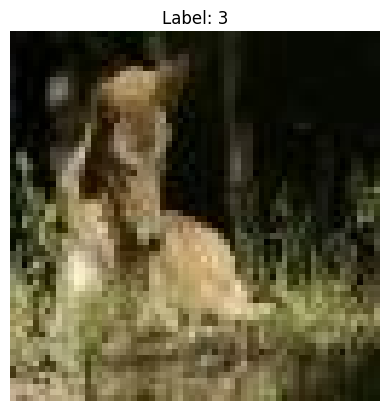

In [36]:
import torch
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import os

def load_data(file_path, id_bytes, label_bytes, num_images, height, width, depth):
    """
    Function to load image data from a binary file.

    Parameters:
    file_path (str): Path to the binary file.
    id_bytes (int): Number of bytes used for the image ID.
    label_bytes (int): Number of bytes used for the image label.
    num_images (int): Number of images in the binary file.
    height (int): Height of the images.
    width (int): Width of the images.
    depth (int): Depth of the images (number of color channels).

    Returns:
    images (torch.Tensor): Tensor of image data.
    labels (torch.Tensor): Tensor of image labels.
    """

    # Define the record size in bytes
    record_size = id_bytes + label_bytes + height * width * depth

    # Initialize tensors to store the image IDs, labels, and data
    ids = torch.empty((num_images, id_bytes), dtype=torch.uint8)
    labels = torch.empty((num_images, label_bytes), dtype=torch.uint8)
    images = torch.empty((num_images, depth, height, width), dtype=torch.uint8)

    # Open the binary file and read the contents
    with open(file_path, 'rb') as file:
        for i in range(num_images):
            byte_record = file.read(record_size)

            # Convert the byte string to a tensor
            byte_tensor = torch.tensor(list(byte_record), dtype=torch.uint8)

            # Extract the image ID
            ids[i] = byte_tensor[:id_bytes].view(1, -1)

            # Extract the image label
            labels[i] = byte_tensor[id_bytes:id_bytes + label_bytes].view(1, -1)

            # Extract the image data
            array_image = byte_tensor[id_bytes + label_bytes:record_size].view(depth, height, width)
            images[i] = array_image

    # Ensure labels is a 1-D tensor
    labels = labels[:, -1]

    return images, labels

# Specify parameters based on dataset information
id_bytes = 4
label_bytes = 4
num_train_images = 50000  # Total training images in Animal-10N
width = 64
height = 64
depth = 3
num_classes = 10

# Path to the binary file
file_path = os.path.join('animal10N', 'data_batch_1.bin')

# Load training data
train_images, train_labels = load_data(file_path, id_bytes, label_bytes, num_train_images, height, width, depth)

# Split training data into training and validation sets
train_images, val_images, train_labels, val_labels = train_test_split(train_images, train_labels, test_size=0.1, random_state=42)

# Print shapes of datasets
print("Training images shape:", train_images.shape)
print("Training labels shape:", train_labels.shape)
print("Validation images shape:", val_images.shape)
print("Validation labels shape:", val_labels.shape)

# Show the second training image
plt.imshow(train_images[1].permute(1, 2, 0))
plt.title(f"Label: {train_labels[1].item()}")
plt.axis('off')
plt.show()


## Question 9

Epoch [1/10]  Loss: 2.3001  Val Acc: 0.4172
Epoch [2/10]  Loss: 2.0540  Val Acc: 0.4040
Epoch [3/10]  Loss: 1.9711  Val Acc: 0.4305
Epoch [4/10]  Loss: 1.9198  Val Acc: 0.4305
Epoch [5/10]  Loss: 1.8929  Val Acc: 0.3642
Epoch [6/10]  Loss: 1.8648  Val Acc: 0.3377
Epoch [7/10]  Loss: 1.8467  Val Acc: 0.3974
Epoch [8/10]  Loss: 1.8274  Val Acc: 0.3311
Epoch [9/10]  Loss: 1.7695  Val Acc: 0.3576
Epoch [10/10]  Loss: 1.7431  Val Acc: 0.3311


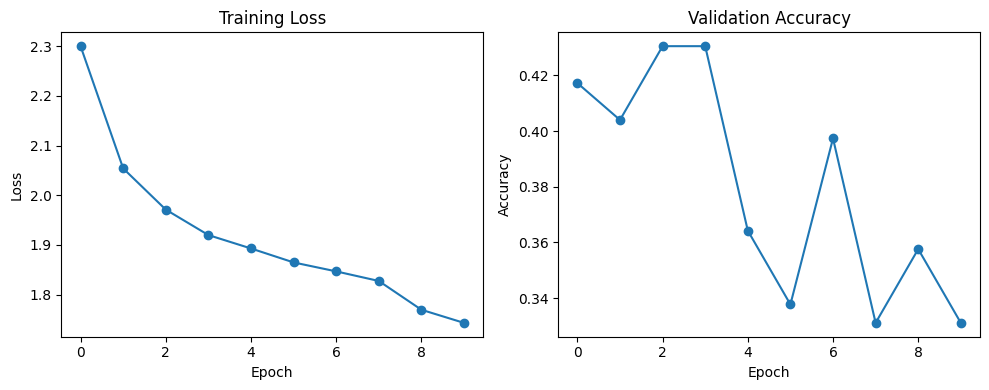

In [21]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, random_split
import matplotlib.pyplot as plt

# (A) Assume train_images: (N, 3, 43, 43) and train_labels: (N,) tensors already loaded

# (B) Normalize image data to [0,1]
if train_images.dtype == torch.uint8:
    images = train_images.float() / 255.0
else:
    images = train_images.clone()
labels = train_labels.long()

# (C) Flatten images for linear model
N = images.shape[0]
X = images.view(N, -1)  # shape: (N, 3*43*43)
y = labels

# (D) Split into train/validation (90/10)
dataset = TensorDataset(X, y)
train_size = int(0.9 * N)
val_size   = N - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

# (E) DataLoaders
batch_size = 128
train_loader_lin = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader_lin   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False)

# (F) Device (GPU if available)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# (G) Single‐layer linear classifier
class LinearAnimalClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.fc = nn.Linear(input_dim, num_classes)
    def forward(self, x):
        return self.fc(x)

input_dim   = X.shape[1]             # 3*43*43
num_classes = len(torch.unique(y))   # should be 10
linear_model = LinearAnimalClassifier(input_dim, num_classes).to(device)

# (H) Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer_lin = torch.optim.Adam(linear_model.parameters(), lr=1e-3)

# (I) Training loop
num_epochs = 10
train_losses = []
val_accuracies = []

for epoch in range(num_epochs):
    linear_model.train()
    running_loss = 0.0
    for inputs, targets in train_loader_lin:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = linear_model(inputs)
        loss = criterion(outputs, targets)

        optimizer_lin.zero_grad()
        loss.backward()
        optimizer_lin.step()
        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / train_size
    train_losses.append(epoch_loss)

    # Validation
    linear_model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, targets in val_loader_lin:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = linear_model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
    val_acc = correct / total
    val_accuracies.append(val_acc)

    print(f"Epoch [{epoch+1}/{num_epochs}]  Loss: {epoch_loss:.4f}  Val Acc: {val_acc:.4f}")

# (J) Plot training loss and validation accuracy
plt.figure(figsize=(10,4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, marker='o')
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, marker='o')
plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.tight_layout()
plt.show()

# (K) Save model checkpoint
torch.save(linear_model.state_dict(), "linear_animal10n_model.pth")


## Question 10

Training on CPU
Training model: VanillaCNN_CPU

=== Epoch 1/15 ===
  [Batch 20] Val Loss: 2.0670, Val Acc: 0.3929
    → New best val acc 0.3929, checkpoint saved at ./saved_models/E1_B20_VanillaCNN_CPU.pt
Epoch 1 summary: Train Loss 2.0726, Train Acc 0.3931 | Val Loss 2.0172, Val Acc 0.3929
Epoch time: 3.72s

=== Epoch 2/15 ===
  [Batch 20] Val Loss: 2.0130, Val Acc: 0.3929
Epoch 2 summary: Train Loss 1.9853, Train Acc 0.4084 | Val Loss 2.0058, Val Acc 0.3929
Epoch time: 2.17s

=== Epoch 3/15 ===
  [Batch 20] Val Loss: 1.9840, Val Acc: 0.3929
Epoch 3 summary: Train Loss 1.9664, Train Acc 0.4084 | Val Loss 1.9880, Val Acc 0.3929
Epoch time: 2.14s

=== Epoch 4/15 ===
  [Batch 20] Val Loss: 1.9973, Val Acc: 0.3929
Epoch 4 summary: Train Loss 1.9486, Train Acc 0.4084 | Val Loss 1.9986, Val Acc 0.3929
Epoch time: 2.19s

=== Epoch 5/15 ===
  [Batch 20] Val Loss: 2.0114, Val Acc: 0.3929
Epoch 5 summary: Train Loss 1.9387, Train Acc 0.4084 | Val Loss 2.0382, Val Acc 0.3929
Epoch time: 2.15s

=

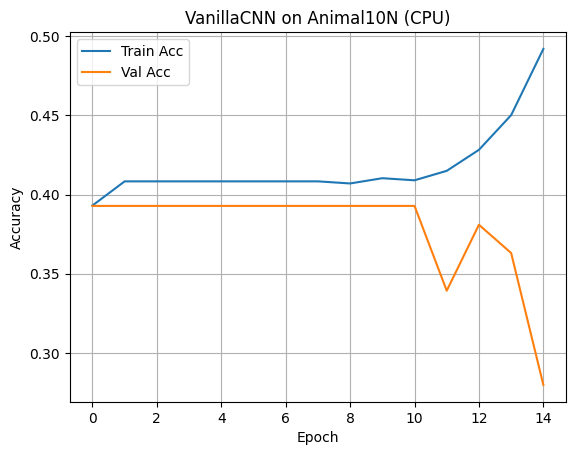

In [ ]:
import os
import time
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# -----------------------------------------
# Step 1: Manual normalization helper
# -----------------------------------------
def normalize(data):
    """
    Normalizes a batch of images by channel-wise mean and std without torchvision.
    Input: data tensor of shape (N, C, H, W), dtype float32 or uint8.
    Returns: float32 tensor of same shape, normalized.
    """
    data = data.to(dtype=torch.float32)
    # Compute per-channel mean and std over (N, H, W)
    mean = data.mean(dim=(0, 2, 3), keepdim=True)  # shape (1, C, 1, 1)
    std = data.std(dim=(0, 2, 3), keepdim=True)    # shape (1, C, 1, 1)
    return (data - mean) / (std + 1e-7)

# -----------------------------------------
# Step 2: Define CNN architecture
# -----------------------------------------
class VanillaCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(VanillaCNN, self).__init__()
        # Input images: (3, 43, 43)

        # Convolutional block
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)                                 # → (32, 21, 21)

        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)                                 # → (64, 10, 10)

        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)                                 # → (128, 5, 5)

        # Fully connected block (flatten size = 128*5*5 = 3200)
        self.fc1 = nn.Linear(in_features=128 * 5 * 5, out_features=256)
        self.fc2 = nn.Linear(in_features=256, out_features=num_classes)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))  # → (N, 32, 21, 21)
        x = self.pool2(F.relu(self.conv2(x)))  # → (N, 64, 10, 10)
        x = self.pool3(F.relu(self.conv3(x)))  # → (N, 128, 5, 5)
        x = x.view(x.size(0), -1)              # flatten → (N, 3200)
        x = F.relu(self.fc1(x))                # → (N, 256)
        x = self.fc2(x)                        # → (N, num_classes)
        return x

# -----------------------------------------
# Step 3: Training loop (CPU only)
# -----------------------------------------
def training_loop(model, dataset_train, dataset_val, epochs, batch_size, lr, save_path, model_name_str):
    """
    Trains the provided model on Animal10N using CPU.
    Returns trained model, best checkpoint path, and metric lists.
    """
    # Explicitly ensure model is on CPU
    device = torch.device("cpu")
    model.to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    train_acc_lst = []
    val_acc_lst = []
    train_loss_lst = []
    val_loss_lst = []

    best_acc = 0.0
    best_model_save_path = None

    print("Training on CPU")
    print("Training model:", model_name_str)

    for epoch_idx in range(epochs):
        print(f"\n=== Epoch {epoch_idx+1}/{epochs} ===")
        epoch_start = time.time()

        # ------------- Training Phase -------------
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        train_loader = DataLoader(dataset_train, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(dataset_val, batch_size=batch_size, shuffle=False)

        for batch_idx, (x, y) in enumerate(train_loader):
            # x and y are already on CPU
            outputs = model(x.float())
            loss = loss_fn(outputs, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            preds = outputs.argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
            running_loss += loss.item() * y.size(0)

            # Validate every 20 batches
            if (batch_idx + 1) % 20 == 0:
                model.eval()
                val_correct = 0
                val_total = 0
                val_running_loss = 0.0

                with torch.no_grad():
                    for vx, vy in val_loader:
                        vout = model(vx.float())
                        vloss = loss_fn(vout, vy)
                        vpreds = vout.argmax(dim=1)
                        val_correct += (vpreds == vy).sum().item()
                        val_total += vy.size(0)
                        val_running_loss += vloss.item() * vy.size(0)

                val_acc_batch = val_correct / val_total
                val_loss_batch = val_running_loss / val_total
                print(f"  [Batch {batch_idx+1}] Val Loss: {val_loss_batch:.4f}, Val Acc: {val_acc_batch:.4f}")

                if val_acc_batch > best_acc:
                    best_acc = val_acc_batch
                    best_model_save_path = os.path.join(
                        save_path, f"E{epoch_idx+1}_B{batch_idx+1}_{model_name_str}.pt"
                    )
                    torch.save(model.state_dict(), best_model_save_path)
                    print(f"    → New best val acc {best_acc:.4f}, checkpoint saved at {best_model_save_path}")
                model.train()

        train_loss_epoch = running_loss / total
        train_acc_epoch = correct / total
        train_loss_lst.append(train_loss_epoch)
        train_acc_lst.append(train_acc_epoch)

        # ------------- Final Validation Phase -------------
        model.eval()
        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for vx, vy in val_loader:
                vout = model(vx.float())
                vloss = loss_fn(vout, vy)
                vpreds = vout.argmax(dim=1)
                val_correct += (vpreds == vy).sum().item()
                val_total += vy.size(0)
                val_running_loss += vloss.item() * vy.size(0)

        val_loss_epoch = val_running_loss / val_total
        val_acc_epoch = val_correct / val_total
        val_loss_lst.append(val_loss_epoch)
        val_acc_lst.append(val_acc_epoch)

        print(f"Epoch {epoch_idx+1} summary: Train Loss {train_loss_epoch:.4f}, Train Acc {train_acc_epoch:.4f} | Val Loss {val_loss_epoch:.4f}, Val Acc {val_acc_epoch:.4f}")
        print(f"Epoch time: {time.time() - epoch_start:.2f}s")

    return model, best_model_save_path, train_acc_lst, val_acc_lst, train_loss_lst, val_loss_lst


# -----------------------------------------
# Step 4: Main execution (CPU only)
# -----------------------------------------
# Create directory for saving checkpoints
save_path = "./saved_models/"
os.makedirs(save_path, exist_ok=True)

# -------------------------------
# Specify Animal10N parameters
# -------------------------------
id_bytes = 4
label_bytes = 4
num_train_images = 50000   # Total images in data_batch_1.bin
width = 43                 # Image width
height = 43                # Image height
depth = 3                  # Number of channels (RGB)
num_classes = 10           # 10 animal categories

# -----------------------------------------
# Load data from binary file
# -----------------------------------------
train_images, train_labels = load_data(
    'animal10N/data_batch_1.bin',
    id_bytes, label_bytes,
    num_train_images,
    height, width, depth
)

# ----- Fix 1: Filter out labels ≥ 10 BEFORE splitting -----
mask = (train_labels < num_classes)
train_images = train_images[mask]
train_labels = train_labels[mask]


# Split into training and validation (90% / 10%)
train_images, val_images, train_labels, val_labels = train_test_split(
    train_images, train_labels,
    test_size=0.1, random_state=42
)

# -----------------------------------------
# Normalize images
# -----------------------------------------
norm_train_images = normalize(train_images)  # shape: (N_train, 3, 43, 43)
norm_val_images   = normalize(val_images)    # shape: (N_val,   3, 43, 43)

# Convert labels to long
train_labels = train_labels.to(torch.long)
val_labels   = val_labels.to(torch.long)

# -----------------------------------------
# Create TensorDatasets
# -----------------------------------------
dataset_train = TensorDataset(norm_train_images, train_labels)
dataset_val   = TensorDataset(norm_val_images,   val_labels)

# -----------------------------------------
# Instantiate model and set hyperparameters
# -----------------------------------------
model = VanillaCNN(num_classes=num_classes)  # Our CPU-only CNN
epochs = 15                                 # Number of epochs
batch_size = 64                             # Mini-batch size
learning_rate = 1e-3                        # Learning rate

from torch.utils.data import DataLoader




# -----------------------------------------
# Run training (all on CPU)
# -----------------------------------------
model, best_model_save_path, train_accs, val_accs, train_losses, val_losses = training_loop(
    model=model,
    dataset_train=dataset_train,
    dataset_val=dataset_val,
    epochs=epochs,
    batch_size=batch_size,
    lr=learning_rate,
    save_path=save_path,
    model_name_str='VanillaCNN_CPU'
)

print("CPU training complete. Best checkpoint at:", best_model_save_path)

# -----------------------------------------
# Plot train/val accuracy
# -----------------------------------------
plt.plot(train_accs, label='Train Acc')
plt.plot(val_accs,   label='Val Acc')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("VanillaCNN on Animal10N (CPU)")
plt.legend()
plt.grid(True)
plt.show()

## Question 11

In [23]:
# Assume the following are already defined:
#   linear_model, optimizer_lin, train_loader_lin, val_loader_lin
#   vanilla_model, optimizer_vanilla, train_loader_cnn, val_loader_cnn
#   criterion
#   TunedCNN class (as above)
#   device = torch.device("cpu")

batch_size_cnn = 64
train_loader_cnn = DataLoader(dataset_train, batch_size=batch_size_cnn, shuffle=True)
val_loader_cnn   = DataLoader(dataset_val,   batch_size=batch_size_cnn, shuffle=False)
optimizer_vanilla = torch.optim.Adam(model.parameters(), lr=1e-3)

# --- Assume the following variables/models are already defined above in your notebook: ---
#   linear_model       (instance of LinearAnimalClassifier, on CPU)
#   optimizer_lin      (optimizer for linear_model)
#   train_loader_lin, val_loader_lin  (DataLoader for linear)
#   VanillaCNN class and vanilla_model (instance of VanillaCNN, on CPU)
#   optimizer_vanilla  (optimizer for vanilla_model)
#   dataset_train, dataset_val        (TensorDatasets of normalized images/labels)
#   criterion          = nn.CrossEntropyLoss()
#
# First, create DataLoaders for the CNNs using dataset_train and dataset_val:
batch_size_cnn = 64
train_loader_cnn = DataLoader(dataset_train, batch_size=batch_size_cnn, shuffle=True)
val_loader_cnn   = DataLoader(dataset_val,   batch_size=batch_size_cnn, shuffle=False)

# 1. Define and instantiate TunedCNN and its optimizer
class TunedCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(TunedCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)
        self.pool1 = nn.MaxPool2d(2, 2)    # → (64, 21, 21)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)
        self.pool2 = nn.MaxPool2d(2, 2)    # → (128, 10, 10)

        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn4   = nn.BatchNorm2d(256)
        self.pool3 = nn.MaxPool2d(2, 2)    # → (256, 5, 5)

        self.fc1 = nn.Linear(256 * 5 * 5, 512)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool1(F.relu(self.bn2(self.conv2(x))))
        x = self.pool2(F.relu(self.bn3(self.conv3(x))))
        x = self.pool3(F.relu(self.bn4(self.conv4(x))))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

device = torch.device("cpu")
tuned_model = TunedCNN(num_classes=10).to(device)
optimizer_tuned = torch.optim.Adam(tuned_model.parameters(), lr=5e-4)

# 2. Prepare metric lists
lin_train_loss = []
lin_val_acc    = []
van_train_loss = []
van_val_acc    = []
tun_train_loss = []
tun_val_acc    = []

num_epochs = 15

# 3. Unified training loop for all three models
for epoch in range(num_epochs):
    print(f"\n--- Epoch {epoch+1}/{num_epochs} ---")

    # --- Linear Model Training ---
    linear_model.train()
    running_loss_lin = 0.0
    total_lin = 0
    for inputs, targets in train_loader_lin:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = linear_model(inputs)
        loss = criterion(outputs, targets)

        optimizer_lin.zero_grad()
        loss.backward()
        optimizer_lin.step()

        running_loss_lin += loss.item() * inputs.size(0)
        total_lin += inputs.size(0)

    epoch_loss_lin = running_loss_lin / total_lin
    lin_train_loss.append(epoch_loss_lin)

    # Linear Validation
    linear_model.eval()
    correct_lin, total_lin = 0, 0
    with torch.no_grad():
        for inputs, targets in val_loader_lin:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = linear_model(inputs)
            _, predicted = torch.max(outputs, 1)
            total_lin += targets.size(0)
            correct_lin += (predicted == targets).sum().item()
    lin_val_acc.append(correct_lin / total_lin)


    # --- Vanilla CNN Training ---
    model.train()
    running_loss_van = 0.0
    total_van = 0
    for imgs, lbls in train_loader_cnn:
        imgs, lbls = imgs.to(device), lbls.to(device)
        outputs = model(imgs)
        loss = criterion(outputs, lbls)

        optimizer_vanilla.zero_grad()
        loss.backward()
        optimizer_vanilla.step()

        running_loss_van += loss.item() * imgs.size(0)
        total_van += imgs.size(0)

    epoch_loss_van = running_loss_van / total_van
    van_train_loss.append(epoch_loss_van)

    # Vanilla CNN Validation
    model.eval()
    correct_van, total_van = 0, 0
    with torch.no_grad():
        for imgs, lbls in val_loader_cnn:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model(imgs)
            _, predicted = torch.max(outputs, 1)
            total_van += lbls.size(0)
            correct_van += (predicted == lbls).sum().item()
    van_val_acc.append(correct_van / total_van)


    # --- Tuned CNN Training ---
    tuned_model.train()
    running_loss_tun = 0.0
    total_tun = 0
    for imgs, lbls in train_loader_cnn:
        imgs, lbls = imgs.to(device), lbls.to(device)
        outputs = tuned_model(imgs)
        loss = criterion(outputs, lbls)

        optimizer_tuned.zero_grad()
        loss.backward()
        optimizer_tuned.step()

        running_loss_tun += loss.item() * imgs.size(0)
        total_tun += imgs.size(0)

    epoch_loss_tun = running_loss_tun / total_tun
    tun_train_loss.append(epoch_loss_tun)

    # Tuned CNN Validation
    tuned_model.eval()
    correct_tun, total_tun = 0, 0
    with torch.no_grad():
        for imgs, lbls in val_loader_cnn:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = tuned_model(imgs)
            _, predicted = torch.max(outputs, 1)
            total_tun += lbls.size(0)
            correct_tun += (predicted == lbls).sum().item()
    tun_val_acc.append(correct_tun / total_tun)


    # --- Print epoch summary ---
    print(
        f"Linear  → Train Loss: {lin_train_loss[-1]:.4f} | Val Acc: {lin_val_acc[-1]:.4f}\n"
        f"Vanilla → Train Loss: {van_train_loss[-1]:.4f} | Val Acc: {van_val_acc[-1]:.4f}\n"
        f"Tuned   → Train Loss: {tun_train_loss[-1]:.4f} | Val Acc: {tun_val_acc[-1]:.4f}"
    )



--- Epoch 1/15 ---
Linear  → Train Loss: 1.6490 | Val Acc: 0.3377
Vanilla → Train Loss: 1.3852 | Val Acc: 0.2976
Tuned   → Train Loss: 2.6422 | Val Acc: 0.3452

--- Epoch 2/15 ---
Linear  → Train Loss: 1.6334 | Val Acc: 0.3642
Vanilla → Train Loss: 1.2092 | Val Acc: 0.3155
Tuned   → Train Loss: 2.0176 | Val Acc: 0.3929

--- Epoch 3/15 ---
Linear  → Train Loss: 1.6102 | Val Acc: 0.3377
Vanilla → Train Loss: 1.0766 | Val Acc: 0.2381
Tuned   → Train Loss: 1.9709 | Val Acc: 0.3929

--- Epoch 4/15 ---
Linear  → Train Loss: 1.5620 | Val Acc: 0.3576
Vanilla → Train Loss: 0.9401 | Val Acc: 0.2619
Tuned   → Train Loss: 1.9748 | Val Acc: 0.3929

--- Epoch 5/15 ---
Linear  → Train Loss: 1.5463 | Val Acc: 0.3245
Vanilla → Train Loss: 0.8176 | Val Acc: 0.2976
Tuned   → Train Loss: 1.9711 | Val Acc: 0.3929

--- Epoch 6/15 ---
Linear  → Train Loss: 1.5357 | Val Acc: 0.3245
Vanilla → Train Loss: 0.6590 | Val Acc: 0.2976
Tuned   → Train Loss: 1.9344 | Val Acc: 0.3929

--- Epoch 7/15 ---
Linear  → Trai

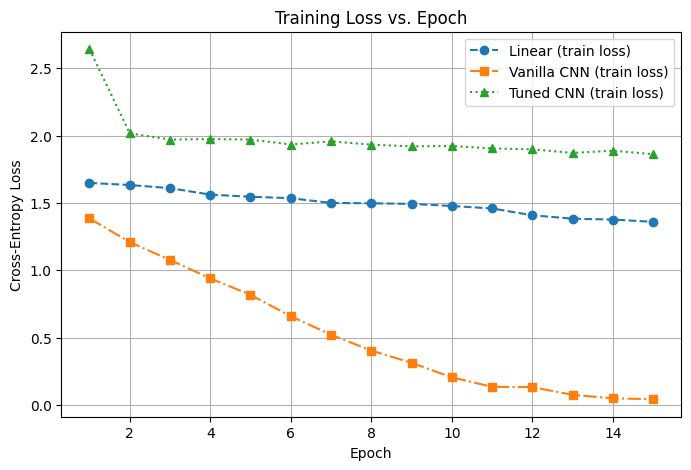

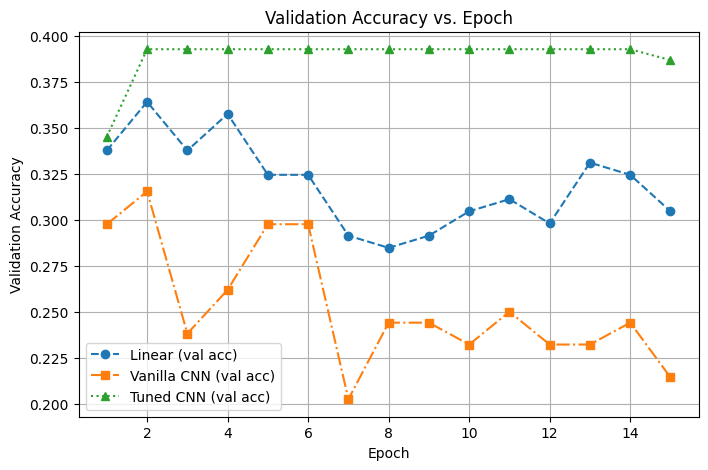

In [24]:
# Assume after training loop you have:
#   lin_train_loss (length = num_epochs)
#   van_train_loss (length = num_epochs)
#   tun_train_loss (length = num_epochs)
#   lin_val_acc    (length = num_epochs)
#   van_val_acc    (length = num_epochs)
#   tun_val_acc    (length = num_epochs)
#   num_epochs defined

import matplotlib.pyplot as plt

epochs_range = list(range(1, num_epochs + 1))

# --- Plot Cross-Entropy Loss vs. Epoch for all three models ---
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, lin_train_loss, label="Linear (train loss)",   linestyle="--", marker="o")
plt.plot(epochs_range, van_train_loss, label="Vanilla CNN (train loss)", linestyle="-.", marker="s")
plt.plot(epochs_range, tun_train_loss, label="Tuned CNN (train loss)",   linestyle=":", marker="^")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training Loss vs. Epoch")
plt.legend()
plt.grid(True)
plt.show()

# --- Plot Validation Accuracy vs. Epoch for all three models ---
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, lin_val_acc, label="Linear (val acc)",   linestyle="--", marker="o")
plt.plot(epochs_range, van_val_acc, label="Vanilla CNN (val acc)", linestyle="-.", marker="s")
plt.plot(epochs_range, tun_val_acc, label="Tuned CNN (val acc)",   linestyle=":", marker="^")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy vs. Epoch")
plt.legend()
plt.grid(True)
plt.show()


## Q12: smoothgrad

[W NNPACK.cpp:64] Could not initialize NNPACK! Reason: Unsupported hardware.
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.2974697..2.5301085].


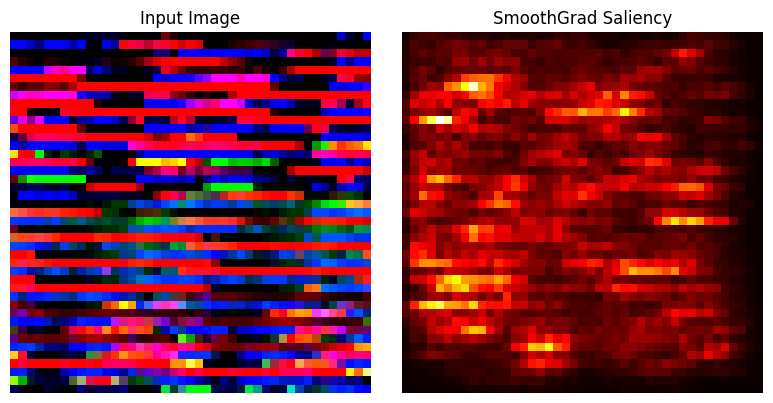

In [26]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F

# Assume `vanilla_model` (trained) and `norm_val_images` (validation images tensor) are already in scope.

# --- Step 1: Define SmoothGrad (reuse from starter) ---
class VanillaGrad:
    """Compute gradient of the model's output w.r.t. input image."""
    def __init__(self, pretrained_model, cuda=False):
        self.pretrained_model = pretrained_model
        self.cuda = cuda

    def __call__(self, x, index=None):
        x.requires_grad_(True)
        output = self.pretrained_model(x)
        if index is None:
            index = output.argmax(dim=1).item()
        one_hot = torch.zeros_like(output)
        one_hot[:, index] = 1
        one_hot = one_hot.to(x.device)
        self.pretrained_model.zero_grad()
        output.backward(gradient=one_hot)
        grad = x.grad.data
        return grad

class SmoothGrad(VanillaGrad):
    """Average gradients over multiple noisy versions of the input."""
    def __init__(self, pretrained_model, cuda=False, stdev_spread=0.15, n_samples=25, magnitude=True):
        super(SmoothGrad, self).__init__(pretrained_model, cuda)
        self.stdev_spread = stdev_spread
        self.n_samples = n_samples
        self.magnitude = magnitude

    def __call__(self, x, index=None):
        stdev = self.stdev_spread * (x.max() - x.min())
        total_gradients = torch.zeros_like(x)
        for _ in range(self.n_samples):
            noise = torch.normal(0, stdev, size=x.shape).to(x.device)
            x_plus_noise = x + noise
            grad = super(SmoothGrad, self).__call__(x_plus_noise, index=index)
            if self.magnitude:
                total_gradients += (grad * grad)
            else:
                total_gradients += grad
        avg_gradients = total_gradients / self.n_samples
        return avg_gradients

# --- Step 2: Prepare model for inference ---
model.eval()  # ensure eval mode

# --- Step 3: Instantiate SmoothGrad with our trained vanilla_model ---
smooth_grad = SmoothGrad(pretrained_model=model, cuda=False, stdev_spread=0.15, n_samples=25, magnitude=True)

# --- Step 4: Select one validation image (e.g., index 0) ---
# norm_val_images: tensor of shape (N_val, 3, 43, 43)
example_idx = 0
example_image = norm_val_images[example_idx]              # shape (3, 43, 43)
example_image_batch = example_image.unsqueeze(0)          # shape (1, 3, 43, 43)

# --- Step 5: Compute SmoothGrad saliency map ---
# Convert to float32 if not already
example_image_batch = example_image_batch.to(dtype=torch.float32)
smooth_saliency = smooth_grad(example_image_batch)       # shape (1, 3, 43, 43)

# --- Step 6: Convert to absolute numpy and sum over channels ---
abs_saliency = smooth_saliency.cpu().numpy()
# abs_saliency shape: (1, 3, 43, 43)
saliency_map = np.sum(abs_saliency, axis=1).squeeze()    # shape (43, 43)

# --- Step 7: Plot original image and saliency heatmap side by side ---
fig, axs = plt.subplots(1, 2, figsize=(8, 4))

# Original image (denormalized to [0,1] for display)
orig = example_image.cpu().numpy().transpose(1, 2, 0)  # (43,43,3)
axs[0].imshow(orig, cmap=None)
axs[0].axis('off')
axs[0].set_title("Input Image")

# SmoothGrad heatmap
axs[1].imshow(saliency_map, cmap='hot')
axs[1].axis('off')
axs[1].set_title("SmoothGrad Saliency")

plt.tight_layout()
plt.show()


#Q13: last q

100%|██████████| 1000/1000 [00:01<00:00, 838.67it/s]


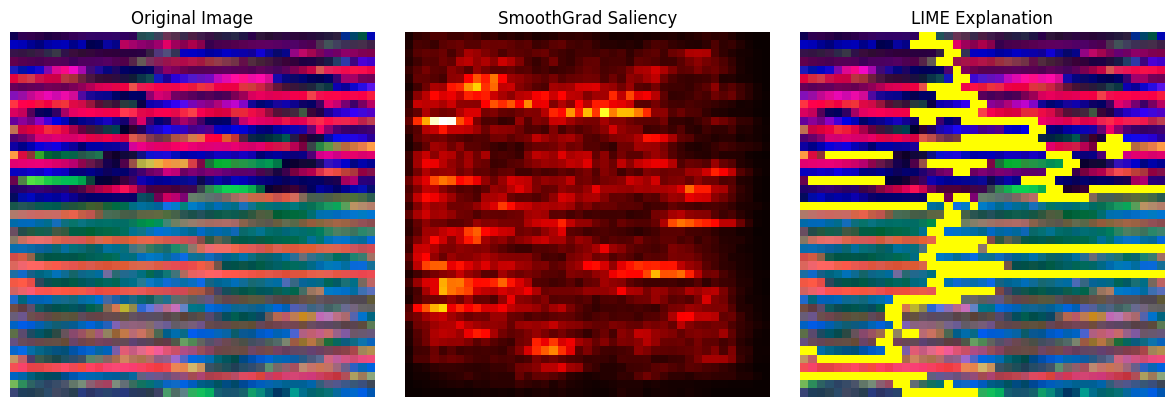

In [33]:
# 1. Redefine your CNN so that it uses reshape(), not view()
class FixedCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(FixedCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(2, 2)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(128 * 5 * 5, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = self.pool3(F.relu(self.conv3(x)))
        x = x.reshape(x.size(0), -1)   # <-- use reshape()
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# 2. Load your trained weights into this corrected class
fixed_model = FixedCNN(num_classes=10).to(device)
fixed_model.load_state_dict(model.state_dict())
fixed_model.eval()

# 3. Update predict_fn to call normalize→FixedCNN
def predict_fn(np_images, cnn_model):
    """
    np_images: numpy array of shape (N, H, W, C) in [0,1].
    Resize → Normalize → forward through cnn_model.
    """
    tensor = (
        torch.from_numpy(np_images * 255.0)
             .permute(0, 3, 1, 2)
             .float()
             .to(device)
    )  # e.g. shape (N, 3, anyH, anyW)

    # Force any input to 43×43
    tensor_resized = F.interpolate(tensor, size=(43, 43), mode='bilinear', align_corners=False)
    tensor_norm = normalize(tensor_resized)

    with torch.no_grad():
        logits = cnn_model(tensor_norm)
        probs = F.softmax(logits, dim=1)
    return probs.cpu().numpy()

# 4. Now run LIME using fixed_model instead of model
from lime import lime_image
from skimage.segmentation import mark_boundaries

explainer = lime_image.LimeImageExplainer()

example_idx = 0
raw_img_tensor = val_images[example_idx]   # (3,43,43) uint8
raw_img_np = raw_img_tensor.permute(1, 2, 0).numpy() / 255.0

explanation = explainer.explain_instance(
    raw_img_np,
    lambda batch: predict_fn(batch, fixed_model),
    top_labels=1,
    hide_color=0,
    num_samples=1000
)

label = explanation.top_labels[0]
temp, mask = explanation.get_image_and_mask(
    label,
    positive_only=True,
    num_features=10,
    hide_rest=False
)

def rescale_image(image):
    mn, mx = image.min(), image.max()
    return (image - mn) / (mx - mn + 1e-5)

normalized_lime = rescale_image(temp)

# 5. Compute SmoothGrad saliency using fixed_model as well
class VanillaGrad:
    def __init__(self, pretrained_model, cuda=False):
        self.pretrained_model = pretrained_model
        self.cuda = cuda

    def __call__(self, x, index=None):
        x.requires_grad_(True)
        output = self.pretrained_model(x)
        if index is None:
            index = output.argmax(dim=1).item()
        one_hot = torch.zeros_like(output)
        one_hot[:, index] = 1
        one_hot = one_hot.to(x.device)
        self.pretrained_model.zero_grad()
        output.backward(gradient=one_hot)
        return x.grad.data

class SmoothGrad(VanillaGrad):
    def __init__(self, pretrained_model, cuda=False, stdev_spread=0.15, n_samples=25, magnitude=True):
        super(SmoothGrad, self).__init__(pretrained_model, cuda)
        self.stdev_spread = stdev_spread
        self.n_samples = n_samples
        self.magnitude = magnitude

    def __call__(self, x, index=None):
        stdev = self.stdev_spread * (x.max() - x.min())
        total_gradients = torch.zeros_like(x)
        for _ in range(self.n_samples):
            noise = torch.normal(0, stdev, size=x.shape).to(x.device)
            x_plus_noise = x + noise
            grad = super(SmoothGrad, self).__call__(x_plus_noise, index=index)
            if self.magnitude:
                total_gradients += grad * grad
            else:
                total_gradients += grad
        return total_gradients / self.n_samples

smooth_grad = SmoothGrad(pretrained_model=fixed_model, cuda=False, stdev_spread=0.15, n_samples=25, magnitude=True)

norm_img = norm_val_images[example_idx].unsqueeze(0)     # (1,3,43,43)
smooth_sal = smooth_grad(norm_img)                        # (1,3,43,43)
saliency_map = np.sum(np.abs(smooth_sal.cpu().numpy()), axis=1).squeeze()  # (43,43)

# 6. Plot side-by-side
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(raw_img_np)
axes[0].axis('off')
axes[0].set_title("Original Image")

axes[1].imshow(saliency_map, cmap='hot')
axes[1].axis('off')
axes[1].set_title("SmoothGrad Saliency")

axes[2].imshow(mark_boundaries(normalized_lime, mask))
axes[2].axis('off')
axes[2].set_title("LIME Explanation")

plt.tight_layout()
plt.show()
